# Section 4: Final Model Diagnostics and Robustness

The diagnostics assess Model 3 on 4,016 parking spaces, retaining the seven selected predictors and the full-sample OLS specification as the primary model. Residual and influence diagnostics, a 1,000-replication bootstrap, and five-fold cross-validation evaluate model assumptions, coefficient sensitivity, and predictive accuracy. Robustness comparisons are interpreted alongside limitations arising from shared tract characteristics, data timing, and demand-responsive pricing.


**Model and sample**


The analysis examines residuals, variance and functional form, followed by coefficient-specific influence, resampling uncertainty, and held-out prediction accuracy. The diagnostic methods include residual and leverage plots, variance tests, RESET, coefficient-specific influence measures, HC1 standard errors, and bootstrap resampling. Model 3 uses the same full-candidate 5% significance screen as Sections 3 and 5; its predictors are price, population density, food-service/retail registrations, total business registrations, transit share, walk share, and TOD pricing.


The sample retains FLAT and TOD meters with complete observations for the 12-candidate comparison-variable list. Income is included only in the sample restriction, not as a predictor in any of the three models. The source-row index is preserved so diagnostics can be linked to SpaceID and BlockFace.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display, Markdown

%matplotlib inline

root = next((folder for folder in [Path.cwd(), *Path.cwd().parents]
             if (folder / "data/processed/parking_cross_section.csv").is_file()), None)
if root is None:
    raise FileNotFoundError("The project data/processed/parking_cross_section.csv file is required.")
parking_full = pd.read_csv(root / "data/processed/parking_cross_section.csv",
                          dtype={"SpaceID": str, "GEOID": str})
parking = parking_full.loc[parking_full["RateType"].isin(["FLAT", "TOD"])].copy()
dependent_variable = "occupancy_rate"
candidate_variables = [
    "price_midpoint", "time_limit_hours", "population_density", "median_income",
    "nearby_restaurant_retail_count", "drive_alone_share", "RateType", "MeterType",
    "housing_density", "transit_share", "walk_share", "nearby_business_count"
]
encoded = pd.get_dummies(parking[candidate_variables], drop_first=True, dtype=int)
data = pd.concat([parking[["occupancy_rate"]], encoded], axis=1).dropna().copy()
y = data["occupancy_rate"]
X = data.drop(columns="occupancy_rate")
assert parking_full["SpaceID"].is_unique
assert parking.loc[data.index, "SpaceID"].is_unique
print("Original / FLAT+TOD / common:", len(parking_full), len(parking), len(data))
print("Candidates / common-sample tracts:", X.shape[1], parking.loc[data.index, "GEOID"].nunique())

# Preserve complete table text in report outputs.
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 100)

from statsmodels.stats.stattools import jarque_bera
from statsmodels.stats.diagnostic import het_breuschpagan, het_white, linear_reset

parking["RateType_TOD"] = parking["RateType"].eq("TOD").astype(int)


Original / FLAT+TOD / common: 4139 4060 4016
Candidates / common-sample tracts: 12 45


In [2]:
print("Common-sample observations:", len(data))
print("Unique spaces:", parking.loc[data.index, "SpaceID"].nunique())
print("Census tracts:", parking.loc[data.index, "GEOID"].nunique())


Common-sample observations: 4016
Unique spaces: 4016
Census tracts: 45


In [3]:
X1 = sm.add_constant(data[["price_midpoint"]])
model1 = sm.OLS(y, X1).fit()

X2 = sm.add_constant(data[[
    "price_midpoint", "population_density",
    "nearby_restaurant_retail_count"
]])
model2 = sm.OLS(y, X2).fit()

In [4]:
# Fixed rule: retain EVERY slope with conventional p < 0.05 in the
# original 12-candidate full OLS model, on the same complete-case sample.
# This is one screen, not repeated p-value deletion or hold-out tuning.
full_model = sm.OLS(y, sm.add_constant(X)).fit()
alpha = 0.05
predictors = [v for v in X.columns if full_model.pvalues[v] < alpha]
legacy_predictors = ["price_midpoint", "time_limit_hours", "population_density",
                     "nearby_restaurant_retail_count", "drive_alone_share",
                     "transit_share", "RateType_TOD"]
X1 = sm.add_constant(data[["price_midpoint"]])
X2 = sm.add_constant(data[["price_midpoint", "population_density", "nearby_restaurant_retail_count"]])
X3 = sm.add_constant(data[predictors])
model1 = sm.OLS(y, X1).fit()
model2 = sm.OLS(y, X2).fit()
model3 = sm.OLS(y, X3).fit()
hc1 = sm.OLS(y, X3).fit(cov_type="HC1")
legacy_model = sm.OLS(y, sm.add_constant(data[legacy_predictors])).fit()
assert set(predictors) == set(full_model.pvalues.drop("const").loc[lambda p: p < alpha].index)
model_check = pd.DataFrame({
    "Model": ["Model 1", "Model 2", "Model 3"],
    "N": [int(model1.nobs), int(model2.nobs), int(model3.nobs)],
    "Adjusted R2": [model1.rsquared_adj, model2.rsquared_adj, model3.rsquared_adj],
    "AIC": [model1.aic, model2.aic, model3.aic],
    "BIC": [model1.bic, model2.bic, model3.bic]
})
display(model_check.round(5))
print("Model 3 predictors:", predictors)

model3_hc1 = sm.OLS(y, X3).fit(cov_type="HC1")


,Model,N,Adjusted R2,AIC,BIC
0,Model 1,4016,0.15657,-2483.67051,-2471.07443
1,Model 2,4016,0.24293,-2915.51726,-2890.32509
2,Model 3,4016,0.29291,-3185.76999,-3135.38566


Model 3 predictors: ['price_midpoint', 'population_density', 'nearby_restaurant_retail_count', 'transit_share', 'walk_share', 'nearby_business_count', 'RateType_TOD']


In [5]:
coefficient_check = pd.DataFrame({
    "Model 1": model1.params,
    "Model 2": model2.params,
    "Model 3": model3.params
})
coefficient_check.style.format("{:.6g}", na_rep="—")

,Model 1,Model 2,Model 3
RateType_TOD,—,—,0.0435671
const,0.42375,0.392626,0.319517
nearby_business_count,—,—,6.66312e-05
nearby_restaurant_retail_count,—,-0.000228152,-0.000534366
population_density,—,4.05622e-06,3.96115e-06
price_midpoint,0.0545148,0.0599909,0.0515432
transit_share,—,—,0.100461
walk_share,—,—,0.282333


In [6]:
display(Markdown(f"All three models use **{len(data):,} unique spaces** in **{parking.loc[data.index, 'GEOID'].nunique()} tracts**. Model 3 has adjusted R² **{model3.rsquared_adj:.5f}**, AIC **{model3.aic:.2f}**, and BIC **{model3.bic:.2f}**. Its predictor definition matches the final specification in Sections 3 and 5."))

All three models use **4,016 unique spaces** in **45 tracts**. Model 3 has adjusted R² **0.29291**, AIC **-3185.77**, and BIC **-3135.39**. Its predictor definition matches the final specification in Sections 3 and 5.

<a id="section-4a"></a>

## 4(a) Linearity


### Inspect the residual plots

Fitted occupancy, residuals, and internally standardized residuals are calculated from Model 3. Residuals are plotted against fitted occupancy, price, and population density to assess changing spread or systematic patterns. The histogram gives a first view of the residual distribution without deleting unusual observations.

In [7]:
fitted = model3.fittedvalues
residuals = model3.resid
influence = model3.get_influence()
standardized = influence.resid_studentized_internal

print("Fitted occupancy outside [0, 1]:", (~fitted.between(0, 1)).sum())
residuals.describe()

Fitted occupancy outside [0, 1]: 4


count    4.016000e+03
mean    -1.447815e-13
std      1.624409e-01
min     -6.289603e-01
25%     -1.118223e-01
50%     -3.077631e-03
75%      1.053216e-01
max      5.901404e-01
dtype: float64

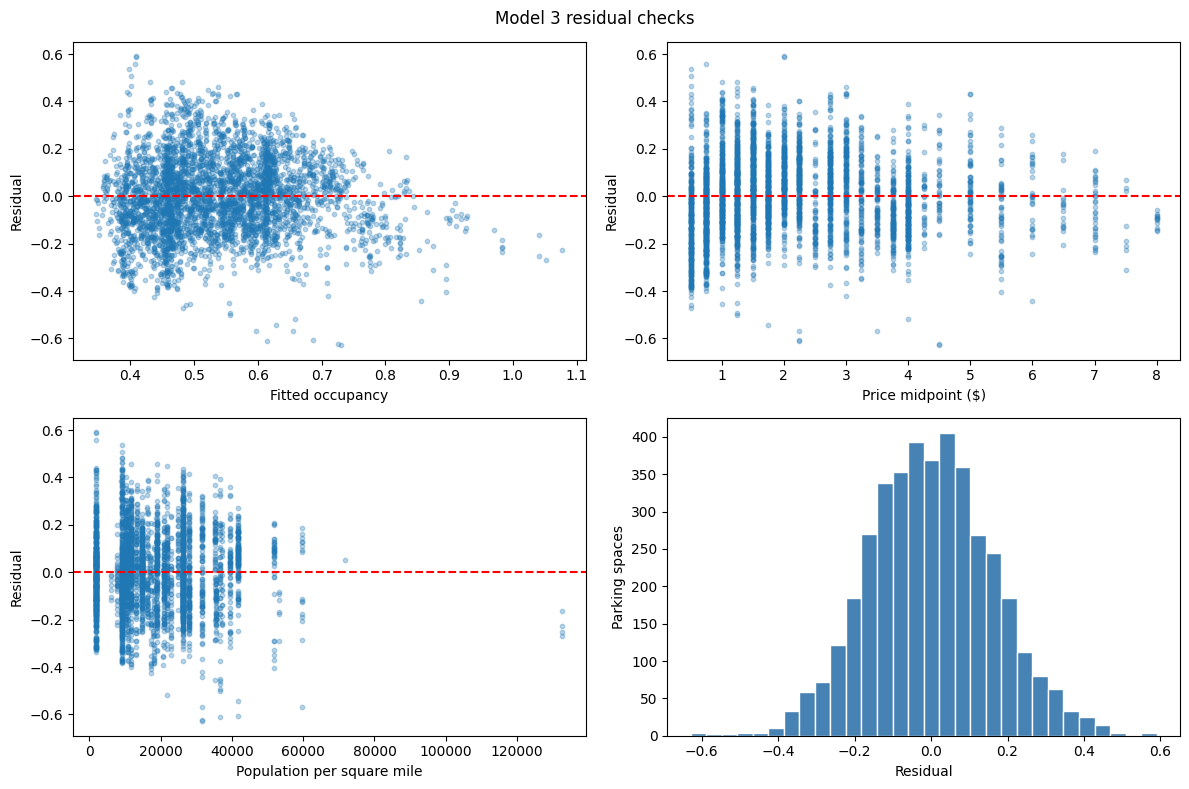

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].scatter(fitted, residuals, s=10, alpha=0.3)
axes[0, 0].set_xlabel("Fitted occupancy")
axes[0, 1].scatter(data["price_midpoint"], residuals, s=10, alpha=0.3)
axes[0, 1].set_xlabel("Price midpoint ($)")
axes[1, 0].scatter(data["population_density"], residuals, s=10, alpha=0.3)
axes[1, 0].set_xlabel("Population per square mile")

axes[0, 0].axhline(0, color="red", linestyle="--")
axes[0, 1].axhline(0, color="red", linestyle="--")
axes[1, 0].axhline(0, color="red", linestyle="--")
axes[0, 0].set_ylabel("Residual")
axes[0, 1].set_ylabel("Residual")
axes[1, 0].set_ylabel("Residual")
axes[1, 1].hist(residuals, bins=30, color="steelblue", edgecolor="white")
axes[1, 1].set_xlabel("Residual")
axes[1, 1].set_ylabel("Parking spaces")
fig.suptitle("Model 3 residual checks")
fig.tight_layout()
plt.show()

In [9]:
display(Markdown(f"Residuals are centered near zero overall and range from **{residuals.min():.3f} to {residuals.max():.3f}**. Their spread is not uniform, and shared tract measurements create vertical bands in the density plot. **{int((~fitted.between(0, 1)).sum())} fitted values lie outside [0, 1]**, a limitation of unconstrained OLS for a bounded outcome. Predictions are not clipped."))

Residuals are centered near zero overall and range from **-0.629 to 0.590**. Their spread is not uniform, and shared tract measurements create vertical bands in the density plot. **4 fitted values lie outside [0, 1]**, a limitation of unconstrained OLS for a bounded outcome. Predictions are not clipped.

### Check the linear functional form

The specification check uses the Ramsey RESET approach, adding the square of fitted values in an auxiliary test. The null is that this added term is unnecessary. A rejection points to a possible specification problem, not to the particular variable or transformation that would fix it.

In [10]:
reset = linear_reset(model3, power=2, test_type="fitted", use_f=True)
print(reset)

<F test: F=171.62862995813222, p=1.9889105346205106e-38, df_denom=4.01e+03, df_num=1>


In [11]:
display(Markdown(f"RESET gives **F = {float(reset.fvalue):.3f}**, **p = {float(reset.pvalue):.3g}**, indicating a functional-form concern at 5%. Because this is the conventional test and heteroskedasticity is present, it is interpreted alongside the residual plots. The right-tailed, positive density variable motivates the log alternative below; the primary specification remains unchanged."))

RESET gives **F = 171.629**, **p = 1.99e-38**, indicating a functional-form concern at 5%. Because this is the conventional test and heteroskedasticity is present, it is interpreted alongside the residual plots. The right-tailed, positive density variable motivates the log alternative below; the primary specification remains unchanged.

### Log-density sensitivity

The following sensitivity comparison assesses whether a log transformation of population density improves functional form. HC1 uncertainty permits comparison with the primary specification.


**Alternative specification**

A natural-log transformation can reduce the skewness of a positive explanatory variable and allow a nonlinear relationship in its original units. The alternative replaces population density only, keeping the same observations, outcome and other six selected predictors; this is a sensitivity check rather than a new primary model.

In [12]:
log_data = data.copy()
assert log_data["population_density"].gt(0).all()
log_data["log_population_density"] = np.log(log_data["population_density"])
log_predictors = ["log_population_density" if v == "population_density" else v for v in predictors]
log_X = sm.add_constant(log_data[log_predictors])
log_model = sm.OLS(y, log_X).fit()
log_hc1 = sm.OLS(y, log_X).fit(cov_type="HC1")
log_reset = linear_reset(log_model, power=2, test_type="fitted", use_f=True)
log_comparison = pd.DataFrame({
    "Specification": ["Original density (primary)", "Log density (robustness)"],
    "N": [int(model3.nobs), int(log_model.nobs)],
    "Price coefficient": [model3.params["price_midpoint"], log_model.params["price_midpoint"]],
    "HC1 price SE": [model3_hc1.bse["price_midpoint"], log_hc1.bse["price_midpoint"]],
    "Adjusted R2": [model3.rsquared_adj, log_model.rsquared_adj],
    "AIC": [model3.aic, log_model.aic],
    "BIC": [model3.bic, log_model.bic],
    "RESET p-value": [float(reset.pvalue), float(log_reset.pvalue)]
})
log_comparison.style.format({"Price coefficient": "{:.6f}", "HC1 price SE": "{:.6f}",
    "Adjusted R2": "{:.5f}", "AIC": "{:.2f}", "BIC": "{:.2f}", "RESET p-value": "{:.3e}"})

,Specification,N,Price coefficient,HC1 price SE,Adjusted R2,AIC,BIC,RESET p-value
0,Original density (primary),4016,0.051543,0.002249,0.29291,-3185.77,-3135.39,1.989e-38
1,Log density (robustness),4016,0.052188,0.002226,0.28578,-3145.51,-3095.13,6.253e-33


In [13]:
display(Markdown(f"With log density, price changes from **{model3.params['price_midpoint']:.5f} to {log_model.params['price_midpoint']:.5f}**. Adjusted R² changes from **{model3.rsquared_adj:.5f} to {log_model.rsquared_adj:.5f}**, and AIC changes from **{model3.aic:.2f} to {log_model.aic:.2f}**. RESET still rejects (**p = {float(log_reset.pvalue):.3g}**). The transformation preserves the positive price association without resolving the specification concern."))

With log density, price changes from **0.05154 to 0.05219**. Adjusted R² changes from **0.29291 to 0.28578**, and AIC changes from **-3185.77 to -3145.51**. RESET still rejects (**p = 6.25e-33**). The transformation preserves the positive price association without resolving the specification concern.

<a id="section-4b"></a>

## 4(b) Homoskedasticity


### Check constant variance and compare robust uncertainty

The variance diagnostics use the scale-location plot, Breusch–Pagan test, and White test. Both tests have a null of constant error variance; their LM and F versions are reported without treating them as separate independent checks. The scale-location plot uses the square root of absolute internally standardized residuals.

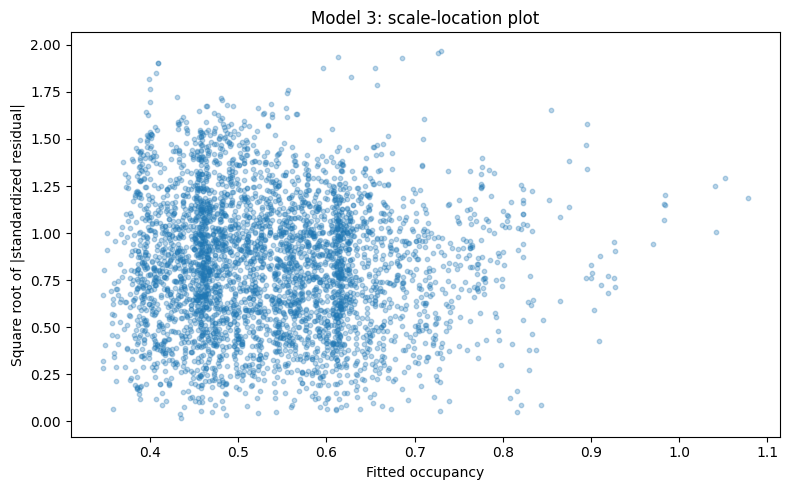

,Test,LM statistic,LM p-value,F statistic,F p-value
0,Breusch–Pagan (default Koenker version),167.020,1.066e-32,24.846,2.109e-33
1,White,374.994,4.538e-59,12.059,2.046e-62


In [14]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(fitted, np.sqrt(np.abs(standardized)), s=10, alpha=0.3)
ax.set_xlabel("Fitted occupancy")
ax.set_ylabel("Square root of |standardized residual|")
ax.set_title("Model 3: scale-location plot")
fig.tight_layout()
plt.show()

bp = het_breuschpagan(residuals, X3)
white = het_white(residuals, X3)
variance_tests = pd.DataFrame({
    "Test": ["Breusch–Pagan (default Koenker version)", "White"],
    "LM statistic": [bp[0], white[0]],
    "LM p-value": [bp[1], white[1]],
    "F statistic": [bp[2], white[2]],
    "F p-value": [bp[3], white[3]]
})
variance_tests.style.format({
    "LM statistic": "{:.3f}", "LM p-value": "{:.3e}",
    "F statistic": "{:.3f}", "F p-value": "{:.3e}"
})

In [15]:
display(Markdown(f"Both tests reject constant variance: the Breusch–Pagan LM p-value is **{bp[1]:.3g}**, and White's is **{white[1]:.3g}**. Conventional standard errors, intervals and tests therefore need caution. HC1 changes uncertainty estimates, not OLS coefficients, and does not correct a misspecified mean. HC1 still treats different spaces as independent."))

Both tests reject constant variance: the Breusch–Pagan LM p-value is **1.07e-32**, and White's is **4.54e-59**. Conventional standard errors, intervals and tests therefore need caution. HC1 changes uncertainty estimates, not OLS coefficients, and does not correct a misspecified mean. HC1 still treats different spaces as independent.

In [16]:
robust_comparison = pd.DataFrame({
    "Coefficient": model3.params,
    "OLS SE": model3.bse,
    "HC1 SE": model3_hc1.bse,
    "OLS p-value": model3.pvalues,
    "HC1 p-value": model3_hc1.pvalues,
    "HC1 95% lower": model3_hc1.conf_int()[0],
    "HC1 95% upper": model3_hc1.conf_int()[1]
})
print("Largest coefficient change:", (model3.params - model3_hc1.params).abs().max())
robust_comparison.style.format({
    "Coefficient": "{:.6g}", "OLS SE": "{:.6g}", "HC1 SE": "{:.6g}",
    "OLS p-value": "{:.3e}", "HC1 p-value": "{:.3e}",
    "HC1 95% lower": "{:.6g}", "HC1 95% upper": "{:.6g}"
})

Largest coefficient change: 0.0


,Coefficient,OLS SE,HC1 SE,OLS p-value,HC1 p-value,HC1 95% lower,HC1 95% upper
const,0.319517,0.00938566,0.0105497,2.359e-223,1.708e-201,0.29884,0.340194
price_midpoint,0.0515432,0.00231509,0.00224949,1.246e-103,3.428e-116,0.0471343,0.0559521
population_density,3.96115e-06,2.16052e-07,2.27304e-07,3.645e-72,5.182e-68,3.51564e-06,4.40665e-06
nearby_restaurant_retail_count,-0.000534366,4.21681e-05,3.8711e-05,4.116e-36,2.412e-43,-0.000610238,-0.000458494
transit_share,0.100461,0.0449134,0.0459653,2.536e-02,2.885e-02,0.0103709,0.190552
walk_share,0.282333,0.0286379,0.0267372,1.136e-22,4.589e-26,0.229929,0.334737
nearby_business_count,6.66312e-05,9.27183e-06,8.88582e-06,7.894e-13,6.451e-14,4.92153e-05,8.40471e-05
RateType_TOD,0.0435671,0.00705204,0.00809947,7.141e-10,7.490e-08,0.0276925,0.0594418


In [17]:
display(Markdown(f"The price estimate stays **{model3.params['price_midpoint']:.5f}**. Its HC1 SE is **{model3_hc1.bse['price_midpoint']:.6f}**, compared with conventional SE **{model3.bse['price_midpoint']:.6f}**; the HC1 95% interval is **[{model3_hc1.conf_int().loc['price_midpoint', 0]:.5f}, {model3_hc1.conf_int().loc['price_midpoint', 1]:.5f}]**. The positive association remains statistically clear. HC1 normal-reference inference does not account for within-tract dependence or model selection."))

The price estimate stays **0.05154**. Its HC1 SE is **0.002249**, compared with conventional SE **0.002315**; the HC1 95% interval is **[0.04713, 0.05595]**. The positive association remains statistically clear. HC1 normal-reference inference does not account for within-tract dependence or model selection.

<a id="section-4c"></a>

## 4(c) Residual Normality


### Check residual normality

The normality assessment compares internally standardized residuals with normal quantiles and uses the Jarque–Bera test, whose null is normal residuals. The histogram is shown in the preceding section rather than repeated here. With a large sample, a test can detect small departures, and failing to reject is not proof of normality.

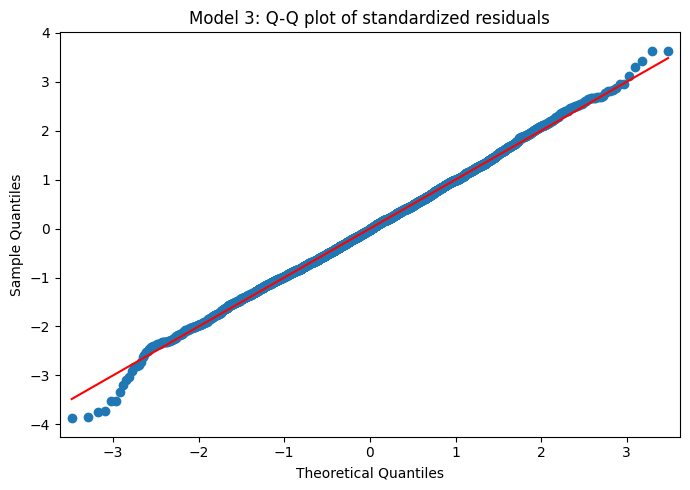

JB statistic    8.075558
P-value         0.017637
Skewness        0.069192
Kurtosis        3.170616
dtype: float64

In [18]:
fig, ax = plt.subplots(figsize=(7, 5))
sm.qqplot(standardized, line="s", ax=ax)
ax.set_title("Model 3: Q-Q plot of standardized residuals")
fig.tight_layout()
plt.show()

jb = jarque_bera(residuals)
normality = pd.Series(jb, index=["JB statistic", "P-value", "Skewness", "Kurtosis"])
normality

In [19]:
display(Markdown(f"Jarque–Bera is **{jb[0]:.3f}**, **p = {jb[1]:.4f}**; residual normality is **{'rejected' if jb[1] < .05 else 'not rejected'} at 5%**. Skewness is **{jb[2]:.3f}** and kurtosis **{jb[3]:.3f}**. The Q-Q plot shows the shape and tail departures. Normality alone does not establish constant variance, independence, or correct conditional-mean specification."))

Jarque–Bera is **8.076**, **p = 0.0176**; residual normality is **rejected at 5%**. Skewness is **0.069** and kurtosis **3.171**. The Q-Q plot shows the shape and tail departures. Normality alone does not establish constant variance, independence, or correct conditional-mean specification.

<a id="section-4d"></a>

## 4(d) Outliers and Influence


### Screen for influential observations

Cook's distance, leverage, and externally studentized residuals are linked back to the unchanged source-row index and parking identifiers. The screening criteria use Cook's **4/n** rule, the **2p/n** leverage rule, and **|standardized or studentized residual| > 2**, where p includes the intercept. These are screening rules, not evidence that a record is incorrect.

In [20]:
diagnostics = parking.loc[data.index, ["SpaceID", "BlockFace", "GEOID"]].copy()
diagnostics["cooks_d"] = influence.cooks_distance[0]
diagnostics["hat_diag"] = influence.hat_matrix_diag
diagnostics["studentized_residual"] = influence.resid_studentized_external
diagnostics["standardized_residual"] = influence.resid_studentized_internal

n = int(model3.nobs)
p = len(model3.params)
cook_cutoff = 4 / n
leverage_cutoff = 2 * p / n

diagnostics["cook_flag"] = diagnostics["cooks_d"] > cook_cutoff
diagnostics["leverage_flag"] = diagnostics["hat_diag"] > leverage_cutoff
diagnostics["residual_flag"] = diagnostics["studentized_residual"].abs() > 2
diagnostics["standardized_flag"] = diagnostics["standardized_residual"].abs() > 2

print("Rows align with the model:", diagnostics.index.equals(model3.model.data.row_labels))
print("n, p (including intercept):", n, p)
print("Cook cutoff:", cook_cutoff)
print("Leverage cutoff:", leverage_cutoff)
diagnostics[["cook_flag", "leverage_flag", "residual_flag", "standardized_flag"]].sum()

Rows align with the model: True
n, p (including intercept): 4016 8
Cook cutoff: 0.00099601593625498
Leverage cutoff: 0.00398406374501992


cook_flag            215
leverage_flag        273
residual_flag        195
standardized_flag    195
dtype: int64

In [21]:
diagnostics.nlargest(10, "cooks_d")[[
    "SpaceID", "BlockFace", "GEOID", "cooks_d", "hat_diag",
    "studentized_residual", "cook_flag", "leverage_flag", "residual_flag"
]]

,SpaceID,BlockFace,GEOID,cooks_d,hat_diag,studentized_residual,cook_flag,leverage_flag,residual_flag
1487,CB3699,601 MAIN ST,06037207308,0.015170,0.009690,-3.526715,True,True,True
1223,CB3169,500 7TH ST,06037207712,0.010469,0.006718,-3.523912,True,True,True
1429,CB3568,700 GRAND AVE,06037207712,0.010217,0.005515,-3.845744,True,True,True
1464,CB3647,501 SPRING ST,06037207304,0.009177,0.025611,-1.671641,True,True,False
1466,CB3648B,501 SPRING ST,06037207304,0.008552,0.027150,-1.566028,True,True,False
1433,CB3570A,700 GRAND AVE,06037207712,0.007784,0.004127,-3.883366,True,True,True
1468,CB3651,601 SPRING ST,06037207304,0.007195,0.028216,-1.408124,True,True,False
1952,CB4486,700 BROADWAY,06037207303,0.007113,0.011367,2.225739,True,True,True
1139,CB2930,600 HILL ST,06037207305,0.004723,0.008326,2.122415,True,True,True
2739,HO482,6301 YUCCA ST,06037190201,0.003741,0.002146,-3.736709,True,False,True


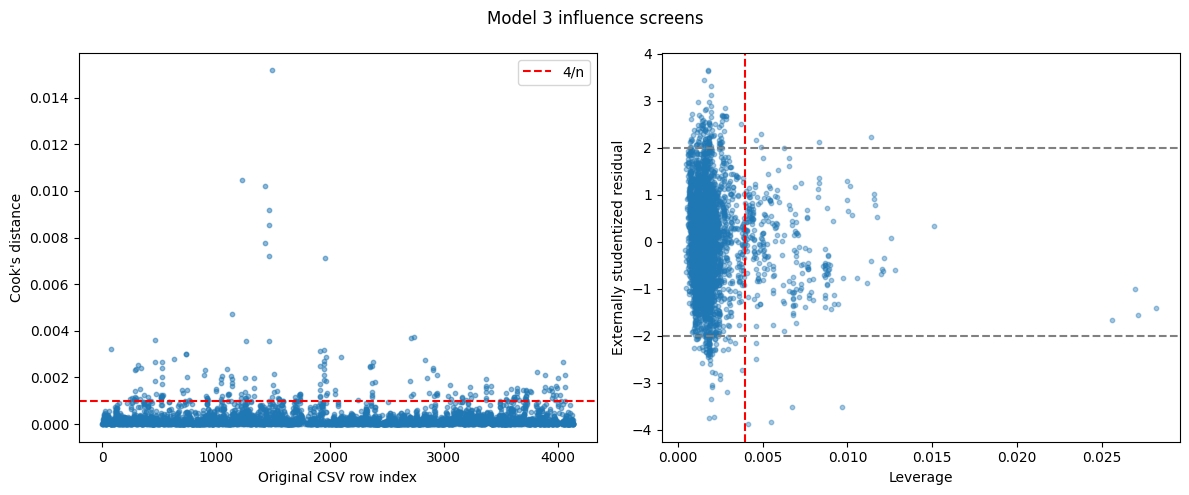

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(diagnostics.index, diagnostics["cooks_d"], s=10, alpha=0.5)
axes[0].axhline(cook_cutoff, color="red", linestyle="--", label="4/n")
axes[0].set_xlabel("Original CSV row index")
axes[0].set_ylabel("Cook's distance")
axes[0].legend()
axes[1].scatter(diagnostics["hat_diag"], diagnostics["studentized_residual"],
                s=10, alpha=0.4)
axes[1].axvline(leverage_cutoff, color="red", linestyle="--")
axes[1].axhline(2, color="grey", linestyle="--")
axes[1].axhline(-2, color="grey", linestyle="--")
axes[1].set_xlabel("Leverage")
axes[1].set_ylabel("Externally studentized residual")
fig.suptitle("Model 3 influence screens")
fig.tight_layout()
plt.show()

In [23]:
display(Markdown(f"The screens flag **{int(diagnostics.cook_flag.sum())}/{n:,}** spaces by Cook's distance, **{int(diagnostics.leverage_flag.sum())}/{n:,}** by leverage, and **{int(diagnostics.residual_flag.sum())}/{n:,}** by externally studentized residuals. The internally standardized-residual screen also flags **{int(diagnostics.standardized_flag.sum())}/{n:,}** spaces at |residual| > 2; these groups overlap. The highest Cook's distance is **{diagnostics.cooks_d.max():.5f}**, at SpaceID **{diagnostics.loc[diagnostics.cooks_d.idxmax(), 'SpaceID']}**. Identifiers and neighborhood context warrant review; flags do not establish incorrect records."))

The screens flag **215/4,016** spaces by Cook's distance, **273/4,016** by leverage, and **195/4,016** by externally studentized residuals. The internally standardized-residual screen also flags **195/4,016** spaces at |residual| > 2; these groups overlap. The highest Cook's distance is **0.01517**, at SpaceID **CB3699**. Identifiers and neighborhood context warrant review; flags do not establish incorrect records.

<a id="model3-dfbetas"></a>

### Coefficient-specific influence: DFBETAS

DFBETAS measures each observation’s standardized contribution to each fitted coefficient: the full-fit coefficient minus its leave-one-observation-out counterpart, standardized using the deletion-based error scale and full-design covariance factor. Columns include the intercept and follow `model3.params.index`. The cutoff **2/√n is a screening rule**, not proof of an erroneous or bad observation. This diagnostic does not change Model 3 or remove any observations.


In [24]:
# Use the fitted model's observation order, retaining original CSV row labels.
dfbetas_model_rows = pd.Index(model3.model.data.row_labels)
dfbetas_values = model3.get_influence().dfbetas
assert dfbetas_values.shape == (int(model3.nobs), len(model3.params))
assert dfbetas_model_rows.is_unique
assert dfbetas_model_rows.equals(X3.index)
assert dfbetas_model_rows.equals(y.index)
assert dfbetas_model_rows.equals(diagnostics.index)
np.testing.assert_allclose(model3.model.exog, X3.loc[dfbetas_model_rows].to_numpy())
np.testing.assert_allclose(model3.model.endog, y.loc[dfbetas_model_rows].to_numpy())
assert np.isfinite(dfbetas_values).all()

dfbetas = pd.DataFrame(
    dfbetas_values, index=dfbetas_model_rows, columns=model3.params.index
)
dfbetas.index.name = "source_row"
assert dfbetas.columns.equals(model3.params.index)
dfbetas_cutoff = 2 / np.sqrt(int(model3.nobs))
print(f"DFBETAS rows verified against model observations: {len(dfbetas):,}")
print(f"Screening rule only: |DFBETAS| > 2/sqrt(n) = {dfbetas_cutoff:.5f}")

# Report magnitude, signed value, and the matching observation for each coefficient.
dfbetas_peak_rows = dfbetas.abs().idxmax()
dfbetas_summary = pd.DataFrame({
    "Max absolute DFBETAS": dfbetas.abs().max(),
    "Signed DFBETAS at maximum": [dfbetas.loc[row, name] for name, row in dfbetas_peak_rows.items()],
    "Source row at maximum": dfbetas_peak_rows,
    "SpaceID at maximum": [parking.loc[row, "SpaceID"] for row in dfbetas_peak_rows],
    "Count above screening rule": dfbetas.abs().gt(dfbetas_cutoff).sum()
})
dfbetas_summary.index.name = "Coefficient"
dfbetas_summary.style.format({
    "Max absolute DFBETAS": "{:.5f}",
    "Signed DFBETAS at maximum": "{:.5f}"
})


DFBETAS rows verified against model observations: 4,016
Screening rule only: |DFBETAS| > 2/sqrt(n) = 0.03156


,Max absolute DFBETAS,Signed DFBETAS at maximum,Source row at maximum,SpaceID at maximum,Count above screening rule
Coefficient,,,,,
const,0.12272,0.12272,1464,CB3647,356
price_midpoint,0.18725,0.18725,1487,CB3699,194
population_density,0.23826,-0.23826,1464,CB3647,197
nearby_restaurant_retail_count,0.12729,0.12729,1429,CB3568,192
transit_share,0.09814,0.09814,73,66183,260
walk_share,0.12171,-0.12171,4043,WV58,202
nearby_business_count,0.21749,-0.21749,1429,CB3568,180
RateType_TOD,0.10630,-0.10630,2100,CB619,348


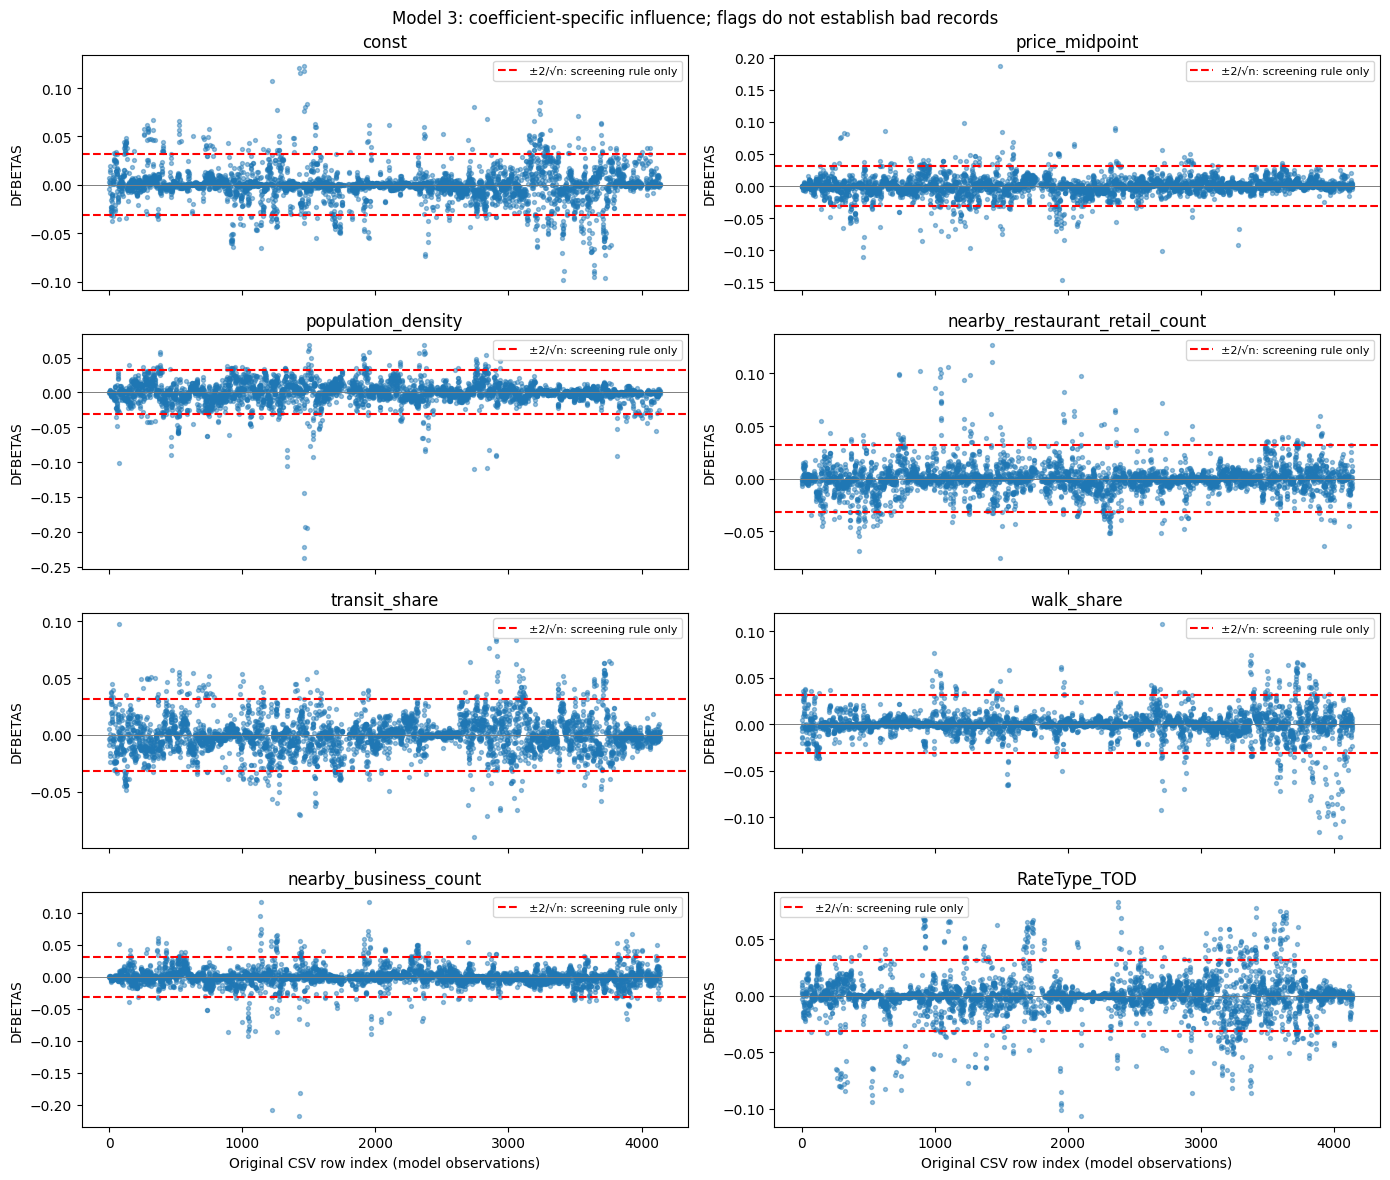

In [25]:
fig, axes = plt.subplots(4, 2, figsize=(14, 12), sharex=True)
for ax, name in zip(axes.flat, dfbetas.columns):
    ax.scatter(dfbetas.index, dfbetas[name], s=8, alpha=0.45)
    ax.axhline(0, color="grey", linewidth=0.7)
    ax.axhline(dfbetas_cutoff, color="red", linestyle="--",
               label="±2/√n: screening rule only")
    ax.axhline(-dfbetas_cutoff, color="red", linestyle="--")
    ax.set_title(name)
    ax.set_ylabel("DFBETAS")
    ax.legend(fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("Original CSV row index (model observations)")
fig.suptitle("Model 3: coefficient-specific influence; flags do not establish bad records")
fig.tight_layout()
plt.show()


In [26]:
from IPython.display import display, Markdown

dfbetas_most_affected = dfbetas_summary["Max absolute DFBETAS"].idxmax()
dfbetas_any_flags = int(dfbetas.abs().gt(dfbetas_cutoff).any(axis=1).sum())
dfbetas_price_peak = dfbetas_summary.loc["price_midpoint"]
display(Markdown(
    f"**DFBETAS interpretation.** {dfbetas_any_flags:,} of {len(dfbetas):,} spaces "
    f"exceed the ±{dfbetas_cutoff:.5f} screening rule for at least one coefficient. "
    f"The largest absolute DFBETAS is "
    f"{dfbetas_summary.loc[dfbetas_most_affected, 'Max absolute DFBETAS']:.5f} "
    f"for **{dfbetas_most_affected}**. For price, the largest absolute value is "
    f"{dfbetas_price_peak['Max absolute DFBETAS']:.5f}, at SpaceID "
    f"**{dfbetas_price_peak['SpaceID at maximum']}**. "
    "The table and panels show which coefficients are most sensitive to individual observations; "
    "the signed values indicate the direction of the full-fit minus deleted-fit change. "
    "Flag counts overlap across coefficients and a low screening threshold can flag many ordinary "
    "observations. These results motivate contextual review, not automatic deletion, and do not "
    "resolve heteroskedasticity, spatial dependence, or endogeneity. "
    "All observations and the original Model 3 remain unchanged."
))
# Guard against unintended changes to the primary model or its sample.
assert int(model3.nobs) == len(dfbetas_model_rows)
np.testing.assert_allclose(model3.params.to_numpy(), np.linalg.lstsq(X3, y, rcond=None)[0])


**DFBETAS interpretation.** 912 of 4,016 spaces exceed the ±0.03156 screening rule for at least one coefficient. The largest absolute DFBETAS is 0.23826 for **population_density**. For price, the largest absolute value is 0.18725, at SpaceID **CB3699**. The table and panels show which coefficients are most sensitive to individual observations; the signed values indicate the direction of the full-fit minus deleted-fit change. Flag counts overlap across coefficients and a low screening threshold can flag many ordinary observations. These results motivate contextual review, not automatic deletion, and do not resolve heteroskedasticity, spatial dependence, or endogeneity. All observations and the original Model 3 remain unchanged.

### Check sensitivity to Cook's-distance flags

The sensitivity analysis refits the same seven-variable specification after excluding only spaces above 4/n for Cook's distance. This is a sensitivity comparison, not a new cleaning rule, and the 4,016-space fit remains primary. Fit statistics across different samples do not establish that the screened sample is a better model.

In [27]:
keep = diagnostics["cooks_d"] <= cook_cutoff
model3_sensitivity = sm.OLS(y.loc[keep], X3.loc[keep]).fit()

sensitivity = pd.DataFrame({
    "Sample": ["Full sample (primary)", "Cook <= 4/n (sensitivity)"],
    "N": [int(model3.nobs), int(model3_sensitivity.nobs)],
    "Price coefficient": [model3.params["price_midpoint"],
                          model3_sensitivity.params["price_midpoint"]],
    "Price p-value": [model3.pvalues["price_midpoint"],
                      model3_sensitivity.pvalues["price_midpoint"]],
    "Adjusted R2": [model3.rsquared_adj, model3_sensitivity.rsquared_adj]
})
sensitivity.style.format({
    "Price coefficient": "{:.6f}", "Price p-value": "{:.3e}", "Adjusted R2": "{:.5f}"
})

,Sample,N,Price coefficient,Price p-value,Adjusted R2
0,Full sample (primary),4016,0.051543,1.246e-103,0.29291
1,Cook <= 4/n (sensitivity),3801,0.053297,2.323e-127,0.36909


In [28]:
sensitivity_coefficients = pd.DataFrame({
    "Full-sample coefficient": model3.params,
    "Sensitivity coefficient": model3_sensitivity.params,
    "Sensitivity p-value": model3_sensitivity.pvalues
})
sensitivity_coefficients.style.format({
    "Full-sample coefficient": "{:.6g}", "Sensitivity coefficient": "{:.6g}",
    "Sensitivity p-value": "{:.3e}"
})

,Full-sample coefficient,Sensitivity coefficient,Sensitivity p-value
const,0.319517,0.306911,1.293e-230
price_midpoint,0.0515432,0.053297,2.323e-127
population_density,3.96115e-06,4.70822e-06,7.426e-108
nearby_restaurant_retail_count,-0.000534366,-0.00061522,2.350e-55
transit_share,0.100461,0.0485782,2.337e-01
walk_share,0.282333,0.293004,1.223e-26
nearby_business_count,6.66312e-05,7.09909e-05,3.181e-16
RateType_TOD,0.0435671,0.0595886,1.373e-19


In [29]:
display(Markdown(f"Excluding **{int((~keep).sum())}** Cook-flagged spaces in the sensitivity fit leaves **{int(model3_sensitivity.nobs):,}** observations. Price changes from **{model3.params['price_midpoint']:.5f} to {model3_sensitivity.params['price_midpoint']:.5f}**, remaining positive. Adjusted R² changes from **{model3.rsquared_adj:.5f} to {model3_sensitivity.rsquared_adj:.5f}**. Screening on residual influence can mechanically improve fit; differences across these samples do not establish superiority. The full sample remains primary, and conventional sensitivity p-values do not resolve heteroskedasticity or dependence."))

Excluding **215** Cook-flagged spaces in the sensitivity fit leaves **3,801** observations. Price changes from **0.05154 to 0.05330**, remaining positive. Adjusted R² changes from **0.29291 to 0.36909**. Screening on residual influence can mechanically improve fit; differences across these samples do not establish superiority. The full sample remains primary, and conventional sensitivity p-values do not resolve heteroskedasticity or dependence.

<a id="section-4e"></a>

## 4(e) Bootstrap


### Bootstrap the preferred specification

The bootstrap samples rows with replacement, fits the same model, and records its coefficients for **1,000 replications**, with seed **90095**. All coefficient estimates are summarized, followed by a focus on price. This holds the selected specification fixed rather than rerunning variable selection in every draw.

In [30]:
np.random.seed(90095)
n_boot = 1000
bootstrap_coefficients = []

for i in range(n_boot):
    sample = data.sample(n=len(data), replace=True)
    X_boot = sm.add_constant(sample[predictors])
    bootstrap_model = sm.OLS(sample["occupancy_rate"], X_boot).fit()
    bootstrap_coefficients.append(bootstrap_model.params)

bootstrap = pd.DataFrame(bootstrap_coefficients)
print("Bootstrap replications:", len(bootstrap))
bootstrap_summary = pd.DataFrame({
    "Original OLS": model3.params,
    "Bootstrap mean": bootstrap.mean(),
    "Bootstrap SE": bootstrap.std(ddof=1),
    "Percentile 95% lower": bootstrap.quantile(0.025),
    "Percentile 95% upper": bootstrap.quantile(0.975)
})
bootstrap_summary.style.format("{:.6g}")

Bootstrap replications: 1000


,Original OLS,Bootstrap mean,Bootstrap SE,Percentile 95% lower,Percentile 95% upper
const,0.319517,0.319355,0.0105967,0.298155,0.34004
price_midpoint,0.0515432,0.0514487,0.00228051,0.0471643,0.0558575
population_density,3.96115e-06,3.97119e-06,2.26831e-07,3.52965e-06,4.4262e-06
nearby_restaurant_retail_count,-0.000534366,-0.000533866,3.82456e-05,-0.000613726,-0.000457751
transit_share,0.100461,0.100415,0.0453937,0.0105158,0.186203
walk_share,0.282333,0.282507,0.0254709,0.23408,0.333398
nearby_business_count,6.66312e-05,6.66684e-05,8.75257e-06,4.85844e-05,8.37852e-05
RateType_TOD,0.0435671,0.0434664,0.00809097,0.0265512,0.0592042


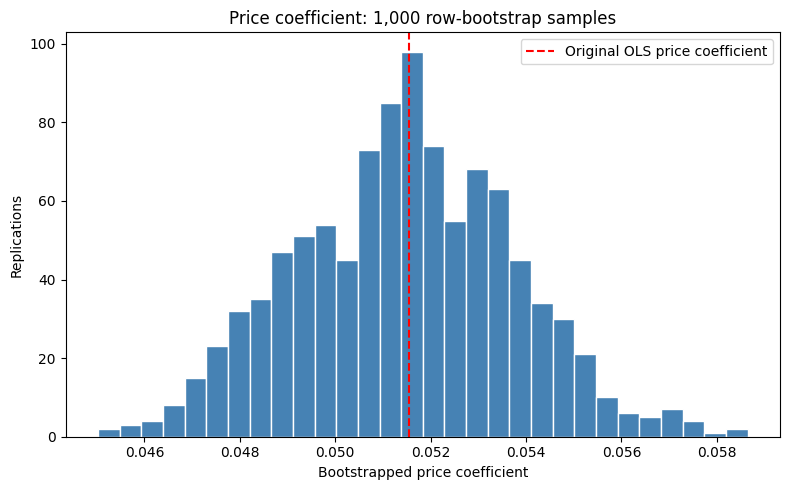

In [31]:
plt.figure(figsize=(8, 5))
plt.hist(bootstrap["price_midpoint"], bins=30, color="steelblue", edgecolor="white")
plt.axvline(model3.params["price_midpoint"], color="red", linestyle="--",
            label="Original OLS price coefficient")
plt.xlabel("Bootstrapped price coefficient")
plt.ylabel("Replications")
plt.title("Price coefficient: 1,000 row-bootstrap samples")
plt.legend()
plt.tight_layout()
plt.show()

In [32]:
display(Markdown(f"The original price coefficient is **{model3.params['price_midpoint']:.5f}**; its bootstrap mean is **{bootstrap_summary.loc['price_midpoint', 'Bootstrap mean']:.5f}**, SE **{bootstrap_summary.loc['price_midpoint', 'Bootstrap SE']:.6f}**, and percentile interval **[{bootstrap_summary.loc['price_midpoint', 'Percentile 95% lower']:.5f}, {bootstrap_summary.loc['price_midpoint', 'Percentile 95% upper']:.5f}]**. Row resampling supports stability of the positive association, conditional on the fixed specification. It assumes independence across spaces despite shared characteristics in 45 tracts, and does not correct endogeneity, mixed source dates, selection uncertainty, or functional form."))

The original price coefficient is **0.05154**; its bootstrap mean is **0.05145**, SE **0.002281**, and percentile interval **[0.04716, 0.05586]**. Row resampling supports stability of the positive association, conditional on the fixed specification. It assumes independence across spaces despite shared characteristics in 45 tracts, and does not correct endogeneity, mixed source dates, selection uncertainty, or functional form.

<a id="section-4f"></a>

## 4(f) Cross-Validation


### Five-fold held-out prediction accuracy

The calculation estimates held-out accuracy using shuffled five-fold splits with seed 10. Each fixed model is fitted on training rows only, and each observation receives exactly one held-out prediction. The results report fold RMSE, its mean and standard deviation, and pooled out-of-fold RMSE. This evaluates the fixed specifications, not the earlier variable-selection process; spatial overlap also limits interpretation as new-neighborhood accuracy.


In [33]:
# Actual held-out predictions for the unchanged specifications, using common folds.
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error

cv_folds = list(KFold(n_splits=5, shuffle=True, random_state=10).split(data))
cv_rows = []
cv_oof = pd.DataFrame(index=data.index)
cv_full_params_before = model3.params.copy()
for cv_name, cv_design in [("Model 1", X1), ("Model 2", X2), ("Model 3", X3)]:
    assert cv_design.index.equals(y.index)
    cv_predictions = pd.Series(np.nan, index=data.index, dtype=float)
    cv_seen = np.zeros(len(data), dtype=int)
    for cv_fold, (cv_train, cv_test) in enumerate(cv_folds, start=1):
        assert not np.intersect1d(cv_train, cv_test).size
        cv_fit = sm.OLS(y.iloc[cv_train], cv_design.iloc[cv_train]).fit()
        cv_pred = cv_fit.predict(cv_design.iloc[cv_test])
        cv_predictions.iloc[cv_test] = cv_pred.to_numpy()
        cv_seen[cv_test] += 1
        cv_rows.append({"Model": cv_name, "Fold": cv_fold,
                        "Training N": len(cv_train), "Held-out N": len(cv_test),
                        "Held-out RMSE": np.sqrt(mean_squared_error(y.iloc[cv_test], cv_pred))})
    assert (cv_seen == 1).all() and cv_predictions.notna().all()
    cv_oof[cv_name] = cv_predictions
cv_fold_results = pd.DataFrame(cv_rows)
cv_summary_actual = cv_fold_results.groupby("Model")["Held-out RMSE"].agg(
    **{"Mean fold RMSE": "mean", "Fold RMSE SD": "std"})
cv_summary_actual["Pooled out-of-fold RMSE"] = [
    np.sqrt(mean_squared_error(y, cv_oof[name])) for name in cv_summary_actual.index]
# Cross-validation uses local fits; the primary Model 3 is untouched.
pd.testing.assert_series_equal(model3.params, cv_full_params_before)
assert int(model3.nobs) == len(data)
display(cv_fold_results.round(5))
display(cv_summary_actual.round(5))
print("Verified five held-out folds per model; each observation predicted once using training-only fits.")
print(f"Model 3 mean fold RMSE: {cv_summary_actual.loc['Model 3', 'Mean fold RMSE']:.5f} "
      f"({100 * cv_summary_actual.loc['Model 3', 'Mean fold RMSE']:.2f} occupancy percentage points).")


,Model,Fold,Training N,Held-out N,Held-out RMSE
0,Model 1,1,3212,804,0.17539
1,Model 1,2,3213,803,0.17974
2,Model 1,3,3213,803,0.17911
3,Model 1,4,3213,803,0.17685
4,Model 1,5,3213,803,0.17673
5,Model 2,1,3212,804,0.16599
6,Model 2,2,3213,803,0.17100
7,Model 2,3,3213,803,0.17081
8,Model 2,4,3213,803,0.16538
9,Model 2,5,3213,803,0.16787


,Mean fold RMSE,Fold RMSE SD,Pooled out-of-fold RMSE
Model,,,
Model 1,0.17756,0.00181,0.17757
Model 2,0.16821,0.00263,0.16822
Model 3,0.16280,0.00135,0.16280


Verified five held-out folds per model; each observation predicted once using training-only fits.
Model 3 mean fold RMSE: 0.16280 (16.28 occupancy percentage points).


In [34]:
display(Markdown(f"Model 3's mean five-fold held-out RMSE is **{cv_summary_actual.loc['Model 3', 'Mean fold RMSE']:.5f}**, or **{100 * cv_summary_actual.loc['Model 3', 'Mean fold RMSE']:.2f} occupancy percentage points**. It has the lowest error of the three fixed specifications. Nearby spaces and common tracts can occur in training and test folds, and selection used this sample. These are held-out-space predictions within the observed setting, not independent validation of the full selection procedure or new-neighborhood accuracy."))

Model 3's mean five-fold held-out RMSE is **0.16280**, or **16.28 occupancy percentage points**. It has the lowest error of the three fixed specifications. Nearby spaces and common tracts can occur in training and test folds, and selection used this sample. These are held-out-space predictions within the observed setting, not independent validation of the full selection procedure or new-neighborhood accuracy.

### Validation with training-only predictor selection

The fixed-specification comparison conditions on predictors selected using the full sample, so it may understate uncertainty from selection. The following five folds repeat the prespecified full-candidate 5% significance screen using training rows only, fit the selected slopes on those same training rows, and predict the held-out rows. The candidate definitions and common complete-case sample remain fixed. Boruta and Cp are comparison tools rather than steps in the final selection rule.

This evaluates the declared selection procedure as well as its fitted coefficients. It does not remove spatial overlap across folds, establish causal identification, or test transfer to another city or future month.

In [35]:
selection_rows = []
selection_oof = pd.Series(np.nan, index=data.index, dtype=float)
selection_seen = np.zeros(len(data), dtype=int)
selection_primary_before = model3.params.copy()
for selection_fold, (selection_train, selection_test) in enumerate(cv_folds, start=1):
    assert not np.intersect1d(selection_train, selection_test).size
    screen = sm.OLS(y.iloc[selection_train],
                    sm.add_constant(X.iloc[selection_train], has_constant="add")).fit()
    fold_predictors = list(screen.pvalues.drop("const").loc[lambda value: value < 0.05].index)
    selection_fit = sm.OLS(y.iloc[selection_train],
                          sm.add_constant(X.iloc[selection_train][fold_predictors], has_constant="add")).fit()
    selection_prediction = selection_fit.predict(
        sm.add_constant(X.iloc[selection_test][fold_predictors], has_constant="add"))
    selection_oof.iloc[selection_test] = selection_prediction.to_numpy()
    selection_seen[selection_test] += 1
    selection_rows.append({"Fold": selection_fold,
                           "Training N": len(selection_train), "Held-out N": len(selection_test),
                           "Selected slopes": len(fold_predictors),
                           "Held-out RMSE": np.sqrt(mean_squared_error(y.iloc[selection_test], selection_prediction)),
                           "Predictors selected on training rows": ", ".join(fold_predictors)})
selection_cv = pd.DataFrame(selection_rows)
assert (selection_seen == 1).all() and selection_oof.notna().all()
pd.testing.assert_series_equal(model3.params, selection_primary_before)
selection_cv_summary = pd.Series({
    "Folds": len(selection_cv),
    "Mean fold RMSE": selection_cv["Held-out RMSE"].mean(),
    "Fold RMSE SD": selection_cv["Held-out RMSE"].std(ddof=1),
    "Pooled out-of-fold RMSE": np.sqrt(mean_squared_error(y, selection_oof))
})
display(selection_cv)
display(selection_cv_summary.to_frame("Training-only selection validation"))
display(Markdown(f"Repeating selection within the training folds gives mean held-out RMSE **{selection_cv_summary['Mean fold RMSE']:.5f}**, or **{100 * selection_cv_summary['Mean fold RMSE']:.2f} occupancy percentage points**, compared with **{cv_summary_actual.loc['Model 3', 'Mean fold RMSE']:.5f}** when the selected specification is held fixed. Each observation is predicted once without using its outcome to select slopes or estimate coefficients for that fold. The full-sample final Model 3 and all fixed-model comparison results remain unchanged."))


,Fold,Training N,Held-out N,Selected slopes,Held-out RMSE,Predictors selected on training rows
0,1,3212,804,9,0.162805,"price_midpoint, population_density, nearby_restaurant_retail_count, housing_density, transit_share, walk_share, nearby_business_count, RateType_TOD, MeterType_Single-Space"
1,2,3213,803,6,0.164126,"price_midpoint, population_density, nearby_restaurant_retail_count, walk_share, nearby_business_count, RateType_TOD"
2,3,3213,803,8,0.164492,"price_midpoint, population_density, nearby_restaurant_retail_count, housing_density, transit_share, walk_share, nearby_business_count, RateType_TOD"
3,4,3213,803,6,0.163102,"price_midpoint, population_density, nearby_restaurant_retail_count, walk_share, nearby_business_count, RateType_TOD"
4,5,3213,803,9,0.162144,"price_midpoint, time_limit_hours, population_density, nearby_restaurant_retail_count, drive_alone_share, walk_share, nearby_business_count, RateType_TOD, MeterType_Single-Space"


,Training-only selection validation
Folds,5.000000
Mean fold RMSE,0.163334
Fold RMSE SD,0.000964
Pooled out-of-fold RMSE,0.163336


Repeating selection within the training folds gives mean held-out RMSE **0.16333**, or **16.33 occupancy percentage points**, compared with **0.16280** when the selected specification is held fixed. Each observation is predicted once without using its outcome to select slopes or estimate coefficients for that fold. The full-sample final Model 3 and all fixed-model comparison results remain unchanged.

<a id="section-4g"></a>

## 4(g) OLS Violations and Implications


### Check coverage and feasible sample sensitivities

The primary outcome uses intervals at most 24 hours and at least 25 transaction-active days. Recorded coverage is inspected first; these checks do not change the sample. The existing data then support a stricter 28-day sample and an income-missingness comparison, keeping the original sample primary.

In [36]:
print("Transaction-active days in the primary sample:")
print(parking.loc[data.index, "active_days"].value_counts().sort_index())

valid_month_fraction = parking.loc[data.index, "total_minutes"] / (31 * 24 * 60)
valid_month_fraction.describe()

Transaction-active days in the primary sample:
active_days
25     356
26    2032
27      19
28      45
29      89
30     184
31    1291
Name: count, dtype: int64


count    4016.000000
mean        0.822536
std         0.117815
min         0.315420
25%         0.741356
50%         0.775555
75%         0.966179
max         0.999898
Name: total_minutes, dtype: float64

Retained valid minutes average **82.25%** of August, with a median of **77.56%** and a minimum of **31.54%**. Active days do not necessarily mean fully monitored days, and the raw sensor records showed Sunday-reporting differences. A 28-day restriction is feasible using the saved active-day count; expanding to 20 days or changing interval cutoffs requires rebuilding the sensor outcomes.

In [37]:
days_data = data.loc[parking.loc[data.index, "active_days"].ge(28)].copy()
days_model = sm.OLS(days_data["occupancy_rate"], sm.add_constant(days_data[predictors])).fit(cov_type="HC1")
income_data = parking[["occupancy_rate", *predictors]].dropna()
income_model = sm.OLS(income_data["occupancy_rate"], sm.add_constant(income_data[predictors])).fit(cov_type="HC1")

sample_checks = pd.DataFrame([
    ["Primary common sample", model3_hc1],
    ["At least 28 active days", days_model],
    ["Retain missing-income spaces", income_model]
], columns=["Sample", "Fit"])
sample_summary = pd.DataFrame({
    "Sample": sample_checks["Sample"],
    "N": [int(m.nobs) for m in sample_checks["Fit"]],
    "Price coefficient": [m.params["price_midpoint"] for m in sample_checks["Fit"]],
    "HC1 95% lower": [m.conf_int().loc["price_midpoint", 0] for m in sample_checks["Fit"]],
    "HC1 95% upper": [m.conf_int().loc["price_midpoint", 1] for m in sample_checks["Fit"]],
    "Adjusted R2": [m.rsquared_adj for m in sample_checks["Fit"]]
})
sample_summary.round(6)

,Sample,N,Price coefficient,HC1 95% lower,HC1 95% upper,Adjusted R2
0,Primary common sample,4016,0.051543,0.047134,0.055952,0.292905
1,At least 28 active days,1609,0.050041,0.042344,0.057738,0.261633
2,Retain missing-income spaces,4060,0.053335,0.048833,0.057837,0.289732


In [38]:
display(Markdown(f"The 28-day sensitivity contains **{int(days_model.nobs):,} spaces** and gives a price coefficient of **{days_model.params['price_midpoint']:.5f}**, compared with **{model3.params['price_midpoint']:.5f}** in the primary fit. Restoring the 44 missing-income spaces gives **{int(income_model.nobs):,} observations** and **{income_model.params['price_midpoint']:.5f}**; income is not a final predictor, so no imputation is needed. Both preserve a positive association, but the 28-day restriction changes composition rather than the interval definition."))

The 28-day sensitivity contains **1,609 spaces** and gives a price coefficient of **0.05004**, compared with **0.05154** in the primary fit. Restoring the 44 missing-income spaces gives **4,060 observations** and **0.05334**; income is not a final predictor, so no imputation is needed. Both preserve a positive association, but the 28-day restriction changes composition rather than the interval definition.

### Limitations of sensor-threshold comparisons

Alternate interval cutoffs were not tested because they require rebuilding occupancy from raw transactions and validating meter and neighborhood-predictor matches. The 28-active-day sensitivity changes sample composition but does not test a different interval definition.


### Diagnostic findings and implications

The summary below combines the tests and robustness checks, keeping screening rules distinct from decisions to change the data. A normality test that does not reject does not offset the variance and functional-form concerns. The price association is stable in the completed sensitivity checks, but its interpretation remains conditional and noncausal.

In [39]:
diagnostic_summary = pd.DataFrame([['Residual plots', 'Uneven spread; tract bands', 'Inspect variance and mean specification; Residual patterns warrant examination of variance and mean specification.'], ['Jarque–Bera', f'p = {jb[1]:.3g}', ('Reject residual normality at 5%' if jb[1] < .05 else 'Do not reject residual normality at 5%') + '; this does not establish other OLS assumptions.'], ['Breusch–Pagan LM', f'p = {bp[1]:.3e}', 'Reject constant variance; HC1 uncertainty is compared separately.'], ['White LM', f'p = {white[1]:.3e}', 'Reject constant variance'], ['RESET', f'p = {float(reset.pvalue):.3e}', 'Possible functional-form problem'], ['Influence', f"{diagnostics['cook_flag'].sum()} Cook flags / {n}", 'Screening flags, not confirmed errors; Flags warrant contextual review.'], ['DFBETAS', f'Max |DFBETAS| = {dfbetas.abs().to_numpy().max():.5f}; {dfbetas_any_flags} spaces flagged', 'Coefficient-specific screening only; Flags do not justify automatic deletion.'], ['Cook sensitivity', f"Price = {model3_sensitivity.params['price_midpoint']:.5f}", 'Positive price association remains; The full sample remains primary.'], ['Row bootstrap', f"{len(bootstrap):,} draws; price CI [{bootstrap_summary.loc['price_midpoint', 'Percentile 95% lower']:.5f}, {bootstrap_summary.loc['price_midpoint', 'Percentile 95% upper']:.5f}]", 'Positive interval; independence assumed; Within-tract dependence remains unresolved.'], ['Five-fold CV', f"Model 3 mean RMSE {cv_summary_actual.loc['Model 3', 'Mean fold RMSE']:.5f} (computed here)", 'Best of the three fixed models; New-neighborhood validity remains unresolved.'], ['Log-density check', f"Price = {log_model.params['price_midpoint']:.5f}; RESET p = {float(log_reset.pvalue):.3e}", 'Price stable; RESET still rejects; The original specification remains primary.'], ['28 active days', f"N = {int(days_model.nobs)}; price = {days_model.params['price_midpoint']:.5f}", 'Positive association in a stricter sample; This changes sample composition, not the interval definition.'], ['Income-missingness sensitivity', f"N = {int(income_model.nobs)}; price = {income_model.params['price_midpoint']:.5f}", 'Retaining missing-income spaces preserves sign; The original common sample remains primary.'], ['Other sensor thresholds', 'Alternate interval cutoffs not estimated', 'Coverage rules may affect Y and sample']], columns=['Diagnostic', 'Result', 'Interpretation'])
# Two narrow, wrapping tables preserve every character without changing values.
from IPython.display import HTML, display
from html import escape

summary_style = """<style>
.section4-summary {width:100%; table-layout:fixed; border-collapse:collapse; margin-bottom:1.5em;}
.section4-summary th, .section4-summary td {
    white-space:normal !important; overflow-wrap:anywhere;
    overflow:visible !important; text-overflow:clip !important;
    text-align:left !important; vertical-align:top; padding:8px;
    border-bottom:1px solid #bbb; max-width:none !important;
}
.section4-summary th:first-child, .section4-summary td:first-child {width:28%;}
</style>"""
summary_fragments = [summary_style]
for summary_title, summary_columns in [
    ("Diagnostic results", ["Diagnostic", "Result"]),
    ("Diagnostic interpretation and caveats", ["Diagnostic", "Interpretation"])
]:
    with pd.option_context("display.max_colwidth", None):
        summary_table = diagnostic_summary[summary_columns].to_html(
            index=False, escape=True, max_rows=None, max_cols=None,
            classes="section4-summary", border=0)
    # Verify the HTML contains each complete value, without Pandas truncation.
    for summary_column in summary_columns:
        for summary_value in diagnostic_summary[summary_column]:
            assert escape(str(summary_value)) in summary_table
    assert "..." not in summary_table and "…" not in summary_table
    summary_fragments.append("<h4>" + escape(summary_title) + "</h4>" + summary_table)
display(HTML("".join(summary_fragments)))


Diagnostic,Result
Residual plots,Uneven spread; tract bands
Jarque–Bera,p = 0.0176
Breusch–Pagan LM,p = 1.066e-32
White LM,p = 4.538e-59
RESET,p = 1.989e-38
Influence,215 Cook flags / 4016
DFBETAS,Max |DFBETAS| = 0.23826; 912 spaces flagged
Cook sensitivity,Price = 0.05330
Row bootstrap,"1,000 draws; price CI [0.04716, 0.05586]"
Five-fold CV,Model 3 mean RMSE 0.16280 (computed here)


In [40]:
display(Markdown(f"The full-sample price coefficient is **{100 * model3.params['price_midpoint']:.2f} occupancy percentage points per $1**. HC1 and row-bootstrap intervals exclude zero. Strong variance and RESET rejections mean the linear model is not fully validated. Residual normality is {'rejected' if jb[1] < .05 else 'not rejected'} at 5%; neither result resolves shared-tract dependence, price endogeneity, or mixed data vintages. The full sample remains primary, influence screens do not become deletion rules, and the log-density comparison does not remove the specification concern."))

The full-sample price coefficient is **5.15 occupancy percentage points per $1**. HC1 and row-bootstrap intervals exclude zero. Strong variance and RESET rejections mean the linear model is not fully validated. Residual normality is rejected at 5%; neither result resolves shared-tract dependence, price endogeneity, or mixed data vintages. The full sample remains primary, influence screens do not become deletion rules, and the log-density comparison does not remove the specification concern.

In [41]:
table_dir = root / "reports/tables"
table_dir.mkdir(parents=True, exist_ok=True)
_diagnostics_export = (table_dir / "current_diagnostics.json").write_text(json.dumps({
    "predictors": predictors, "n": int(model3.nobs),
    "tests": {"BP LM": {"Statistic": bp[0], "p": bp[1]},
              "White LM": {"Statistic": white[0], "p": white[1]},
              "RESET F": {"Statistic": float(reset.fvalue), "p": float(reset.pvalue)},
              "Jarque–Bera": {"Statistic": jb[0], "p": jb[1]}},
    "bootstrap_draws": len(bootstrap),
    "bootstrap": json.loads(bootstrap_summary.to_json(orient="index")),
    "dfbetas": json.loads(dfbetas_summary.to_json(orient="index")),
    "any_dfbetas_flags": dfbetas_any_flags,
    "dfbetas_cutoff": dfbetas_cutoff,
    "model_coefficients": model3.params.to_dict(),
    "influence_screens": diagnostics[["cook_flag", "leverage_flag", "residual_flag", "standardized_flag"]].sum().to_dict(),
    "dfbetas_rows": len(dfbetas),
    "dfbetas_columns": list(dfbetas.columns),
    "cross_validation": json.loads(cv_summary_actual.to_json(orient="index")),
    "selection_aware_cross_validation": selection_cv_summary.to_dict(),
    "selection_aware_folds": json.loads(selection_cv.to_json(orient="records")),
    "robustness": json.loads(sample_summary.set_index("Sample").to_json(orient="index"))
}, indent=2))
